# Circular cylinder: backscattering and shadow

Two cross-sectional cuts for a metal cylinder with radius $7\lambda$. The reference is the 2D analytical solution for an infinitely long PEC cylinder with plane-wave incidence. Ray tracing uses a finite faceted conductor and a distant point transmitter. The meshes are generated below; no external scene files are needed.

- **Fine mesh:** magnitude of the scattered field, with reflection and single-edge diffraction.
- **Coarse mesh:** magnitude of the total field around the geometric shadow, with and without edge-to-edge diffraction.

Both cuts show HH (TE$_z$) and VV (TM$_z$). `0°` is backscatter (toward the source); `180°` is forward scatter. Run top to bottom in the TensorFlow version of Sionna RT with the extended diffraction solver.

In [36]:
from pathlib import Path
from tempfile import TemporaryDirectory
from types import SimpleNamespace
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import c
import tensorflow as tf

from sionna.rt import PlanarArray, Receiver, Transmitter, load_scene
from sionna.rt.analytical_equations import (
    cylinder_te_inc_scat_total,
    cylinder_tm_inc_scat_total,
)
from sionna.rt.paths import Paths

FREQUENCY_HZ = 2.0e9
RADIUS_IN_WAVELENGTHS = 7.0
RX_RADIUS_IN_WAVELENGTHS = 40.0
TX_DISTANCE_M = 400.0
CYLINDER_HEIGHT_M = 20.0

FINE_SIDES = 96
COARSE_SIDES = 14
ANGLE_STEP_DEG = 0.5
SHADOW_MARGIN_DEG = 5.0
# The VH antenna array stores V in slot 0 and H in slot 1.
CO_POLARIZATIONS = {"HH": 1, "VV": 0}
DTYPE = tf.complex64

wavelength = c / FREQUENCY_HZ
radius = RADIUS_IN_WAVELENGTHS * wavelength
rx_radius = RX_RADIUS_IN_WAVELENGTHS * wavelength
k = 2 * np.pi / wavelength
tx_position = np.array([TX_DISTANCE_M, 0.0, 0.0])

print(f"Radius: {radius:.3f} m ({RADIUS_IN_WAVELENGTHS:g} wavelengths)")
print(f"Azimuthal facets: {FINE_SIDES} fine / {COARSE_SIDES} coarse")


Radius: 1.049 m (7 wavelengths)
Azimuthal facets: 96 fine / 14 coarse


In [37]:
def cylinder_mesh(n_sides, radius, height):
    """Make a closed cylinder with axial edges and outward face winding."""
    if n_sides < 3 or radius <= 0 or height <= 0:
        raise ValueError("Expected at least 3 sides, positive radius and height.")

    az = 2 * np.pi * (np.arange(n_sides) + 0.2) / n_sides
    xy = radius * np.column_stack((np.cos(az), np.sin(az)))
    lower = np.column_stack((xy, np.full(n_sides, -height / 2)))
    upper = np.column_stack((xy, np.full(n_sides, height / 2)))
    vertices = np.vstack((lower, upper, [0, 0, -height / 2], [0, 0, height / 2]))

    faces = []
    for i in range(n_sides):
        j = (i + 1) % n_sides
        u, v = i + n_sides, j + n_sides
        faces.extend(((i, j, v), (i, v, u),
                      (2 * n_sides, j, i), (2 * n_sides + 1, u, v)))
    return vertices, np.asarray(faces)


def write_ply(path, vertices, faces):
    header = (
        "ply\nformat ascii 1.0\n"
        f"element vertex {len(vertices)}\n"
        "property float x\nproperty float y\nproperty float z\n"
        f"element face {len(faces)}\n"
        "property list uchar int vertex_indices\nend_header\n"
    )
    with path.open("w", encoding="ascii") as file:
        file.write(header)
        np.savetxt(file, vertices, fmt="%.9g")
        np.savetxt(file, np.column_stack((np.full(len(faces), 3), faces)), fmt="%d")


def receiver_positions(az_deg):
    az = np.deg2rad(az_deg)
    return rx_radius * np.column_stack((np.cos(az), np.sin(az), np.zeros_like(az)))


def setup_scene(n_sides, az_deg):
    vertices, faces = cylinder_mesh(n_sides, radius, CYLINDER_HEIGHT_M)
    with TemporaryDirectory() as folder:
        folder = Path(folder)
        write_ply(folder / "cylinder.ply", vertices, faces)
        xml = folder / "cylinder.xml"
        xml.write_text(
            '<scene version="3.0.0">\n'
            '  <bsdf type="diffuse" id="mat-itu_metal"/>\n'
            '  <shape type="ply" id="mesh-cylinder">\n'
            '    <string name="filename" value="cylinder.ply"/>\n'
            '    <boolean name="face_normals" value="true"/>\n'
            '    <ref id="mat-itu_metal"/>\n'
            '  </shape>\n'
            '</scene>\n',
            encoding="utf-8",
        )
        scene = load_scene(str(xml), dtype=DTYPE)

    scene.frequency = FREQUENCY_HZ
    scene.synthetic_array = True
    scene.tx_array = PlanarArray(
        num_rows=1, num_cols=1, vertical_spacing=0.5, horizontal_spacing=0.5,
        pattern="iso", polarization="VH", dtype=DTYPE,
    )
    scene.rx_array = scene.tx_array
    scene.add(Transmitter("tx", position=tx_position, dtype=DTYPE))
    for i, xyz in enumerate(receiver_positions(az_deg)):
        scene.add(Receiver(f"rx_{i:04d}", position=xyz, dtype=DTYPE))
    return scene


Analytical fields are normalized to a unit incident plane wave. RT path coefficients are summed **coherently** using absolute delays and divided by the free-space channel magnitude $\lambda/(4\pi d)$ at each RX, where $d$ is its distance from the TX. The analytical and RT curves use this common incident-field reference without fitting a dB offset. For the 2D comparison, paths touching the end caps or their rims are excluded; their count is reported below.

In [38]:
def analytical_fields(az_deg, pol):
    solution = {
        "HH": cylinder_te_inc_scat_total,
        "VV": cylinder_tm_inc_scat_total,
    }[pol]
    return solution(np.deg2rad(az_deg), radius, rx_radius, k, terms=512)


def db(field):
    return 20 * np.log10(np.maximum(np.abs(field), 1e-12))


def rt_fields(scene, az_deg, *, include_los, include_ee):
    paths = scene.compute_paths(
        max_depth=1, method="exhaustive",
        los=include_los, reflection=True,
        diffraction=True, edge_diffraction=False, vertex_diffraction=False,
        double_diffraction=include_ee, refl_diff=False, scattering=False,
    )
    paths.normalize_delays = False
    a, _ = paths.cir()
    amplitudes = np.asarray(a)[0, :, :, 0, :, :, 0]  # [rx, rx_pol, tx_pol, path]
    valid = np.asarray(paths.mask, dtype=bool)[0, :, 0, :]
    types = np.asarray(paths.types).reshape(-1)

    # Cap/rim interactions are outside the cross-sectional comparison.
    z = np.asarray(paths.vertices)[:, :, 0, :, 2]
    interacted = np.asarray(paths.objects)[:, :, 0, :] >= 0
    cap = np.any(interacted & (np.abs(z) >= CYLINDER_HEIGHT_M / 2 - 1e-4), axis=0)
    keep = valid & ~cap
    free_space = wavelength / (
        4 * np.pi * np.linalg.norm(receiver_positions(az_deg) - tx_position, axis=-1)
    )
    fields = {}
    finite_co_pol = np.zeros_like(keep)
    for pol, ant in CO_POLARIZATIONS.items():
        co_pol = amplitudes[:, ant, ant, :]
        finite = np.isfinite(co_pol)
        finite_co_pol |= finite
        invalid_count = np.count_nonzero(keep & ~finite)
        if invalid_count:
            warnings.warn(f"{pol}: skipping {invalid_count} non-finite RT path coefficients.")
        fields[pol] = np.sum(np.where(keep & finite, co_pol, 0j), axis=-1) / free_space

    counts = {
        "excluded_cap_paths": np.count_nonzero(valid & cap),
        "valid_ee_paths": np.count_nonzero(
            keep & finite_co_pol & (types[None, :] == Paths.DOUBLE_DIFF)
        ),
    }
    return fields, counts


## 1. Backscattering — fine mesh

The receiver sweep is centered on the source-facing direction. The direct path is disabled so the comparison uses the scattered field alone.

In [39]:
back_deg = np.arange(-110.0, 110.0 + 1e-9, ANGLE_STEP_DEG)
scene = setup_scene(FINE_SIDES, back_deg)

back_rt, back_counts = rt_fields(scene, back_deg, include_los=False, include_ee=False)
back_ref = {pol: analytical_fields(back_deg, pol)[1] for pol in CO_POLARIZATIONS}
print("Cap/rim paths excluded:", back_counts["excluded_cap_paths"])


num_edges: tf.Tensor(0, shape=(), dtype=int32)
num_wedges: 288
Cap/rim paths excluded: 54


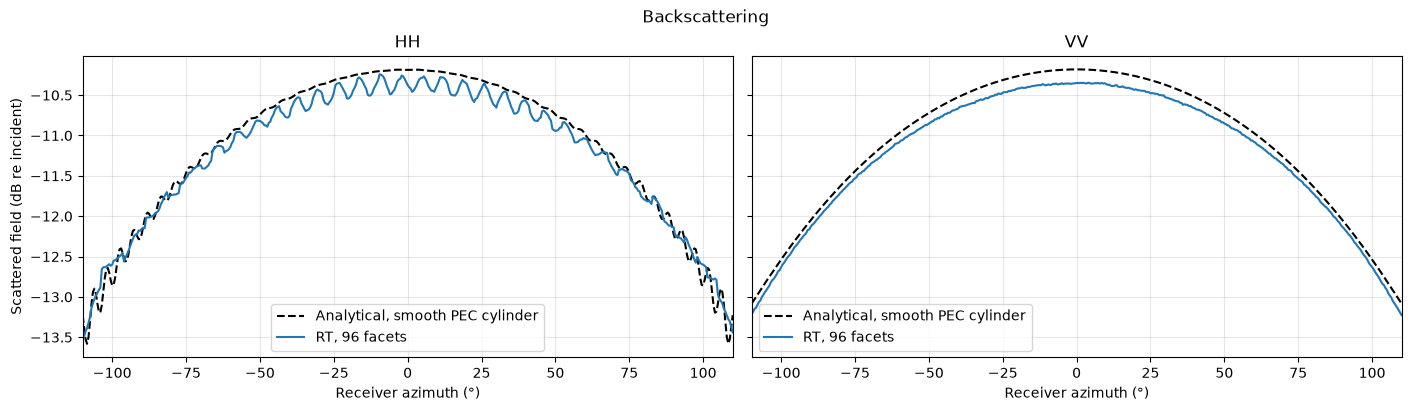

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True, layout="constrained")
fig.suptitle("Backscattering")
for ax, pol in zip(axes, CO_POLARIZATIONS):
    ax.plot(back_deg, db(back_ref[pol]), "k--", label="Analytical, smooth PEC cylinder")
    ax.plot(back_deg, db(back_rt[pol]), label=f"RT, {FINE_SIDES} facets")
    ax.set(
        title=pol,
        xlabel="Receiver azimuth (°)",
        xlim=(back_deg[0], back_deg[-1]),
    )
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Scattered field (dB re incident)")
plt.show()


## 2. Shadow — coarse mesh

Find the two shadow boundaries from the direct-ray mask of the coarse mesh. Plot the shadow and 5° beyond each boundary. The two RT runs share the same scene and settings; the only change is enabling edge-to-edge diffraction. Both use the total field, including the direct ray wherever it is visible.

In [41]:
def shadow_bounds(scene, az_deg):
    paths = scene.compute_paths(
        max_depth=1, method="exhaustive",
        los=True, reflection=False, diffraction=False,
        vertex_diffraction=False, double_diffraction=False, scattering=False,
    )
    illuminated = np.any(np.asarray(paths.mask, dtype=bool)[0, :, 0, :], axis=-1)
    crossing = np.flatnonzero(illuminated[1:] != illuminated[:-1])
    if len(crossing) != 2 or not (illuminated[0] and illuminated[-1]):
        raise RuntimeError("Expected one shadow bracketed by LOS. Check the azimuth sweep.")
    return (az_deg[crossing] + az_deg[crossing + 1]) / 2


shadow_deg = np.arange(145.0, 215.0 + 1e-9, ANGLE_STEP_DEG)
scene = setup_scene(COARSE_SIDES, shadow_deg)
left_sb, right_sb = shadow_bounds(scene, shadow_deg)
shadow_xlim = (left_sb - SHADOW_MARGIN_DEG, right_sb + SHADOW_MARGIN_DEG)

if shadow_xlim[0] < shadow_deg[0] or shadow_xlim[1] > shadow_deg[-1]:
    raise ValueError("The azimuth sweep does not cover both shadow margins.")
print(f"Coarse-mesh shadow: {left_sb:.2f}° to {right_sb:.2f}°")


num_edges: tf.Tensor(0, shape=(), dtype=int32)
num_wedges: 42
Coarse-mesh shadow: 169.75° to 190.25°


In [42]:
solver = scene._solver_paths
dd = solver.double_diffraction
dd.is_wedge_wedge = True
dd.is_ww_analytical = True
dd.is_only_coplanar = True
dd.is_only_in_nlos = False
dd.is_only_close_2_transition = False
dd.is_wedge_vertex = False
dd.is_vertex_wedge = False
dd.is_vertex_vertex = False
dd.is_wedge_wedge_sv = False
dd.is_eee = False

# Exhaustive EE uses the analytical GFI fallback and no EV/VD geometry tables.
solver.obj_geom = SimpleNamespace(diffraction_tables=None, is_glass_transmission=False)

shadow_first, first_counts = rt_fields(
    scene, shadow_deg, include_los=True, include_ee=False
)
shadow_ee, ee_counts = rt_fields(
    scene, shadow_deg, include_los=True, include_ee=True
)
shadow_ref = {pol: analytical_fields(shadow_deg, pol)[2] for pol in CO_POLARIZATIONS}

print("Cap/rim paths excluded:", first_counts["excluded_cap_paths"],
      "(first order),", ee_counts["excluded_cap_paths"], "(with EE)")
print("Valid EE paths across the sweep:", ee_counts["valid_ee_paths"])
if not ee_counts["valid_ee_paths"]:
    warnings.warn("No EE paths were found; check the solver build and scene settings.")


Cap/rim paths excluded: 0 (first order), 42 (with EE)
Valid EE paths across the sweep: 509


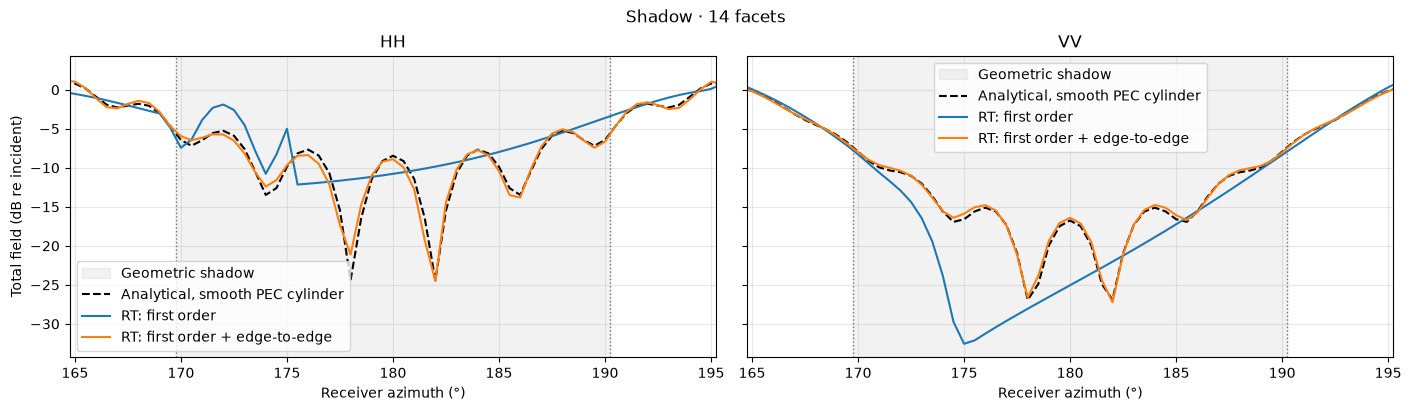

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True, layout="constrained")
fig.suptitle(f"Shadow · {COARSE_SIDES} facets")
for ax, pol in zip(axes, CO_POLARIZATIONS):
    ax.axvspan(left_sb, right_sb, color="0.5", alpha=0.10, label="Geometric shadow")
    for boundary in (left_sb, right_sb):
        ax.axvline(boundary, color="0.45", ls=":", lw=1)

    ax.plot(shadow_deg, db(shadow_ref[pol]), "k--", label="Analytical, smooth PEC cylinder")
    ax.plot(shadow_deg, db(shadow_first[pol]), label="RT: first order")
    ax.plot(shadow_deg, db(shadow_ee[pol]), label="RT: first order + edge-to-edge")
    ax.set(
        title=pol,
        xlabel="Receiver azimuth (°)",
        xlim=shadow_xlim,
    )
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Total field (dB re incident)")
plt.show()
